### Import Library

In [11]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix
)

### Memuat data siap pakai dari hasil Tahap 6

In [12]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Menyiapkan Kategori Harga (Murah, Sedang, Mahal)

In [13]:
# Batas kuartil diambil dari y_train (0 = Murah, 1 = Sedang, 2 = Mahal)
_, bins = pd.qcut(y_train, q=3, retbins=True, labels=[0, 1, 2])
bins[0], bins[-1] = -float('inf'), float('inf')

### Mengubah y_train dan y_test menjadi kategori kelas (0, 1, 2)

In [14]:
y_train_kelas = pd.cut(y_train, bins=bins, labels=[0, 1, 2]).astype(int)
y_test_kelas  = pd.cut(y_test, bins=bins, labels=[0, 1, 2]).astype(int)

### Mencari Kernel Terbaik untuk SVM

In [15]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
acc_scores = []

for k in kernels:
    svm_temp = SVC(kernel=k, random_state=42)
    svm_temp.fit(X_train, y_train_kelas)
    y_pred_temp = svm_temp.predict(X_test)
    acc_scores.append(accuracy_score(y_test_kelas, y_pred_temp))

best_kernel = kernels[np.argmax(acc_scores)]
print(f"Kernel terbaik adalah: {best_kernel} dengan Accuracy: {max(acc_scores):.4f}")

Kernel terbaik adalah: rbf dengan Accuracy: 0.6906


### Visualisasi perbandingan Kernel vs Accuracy

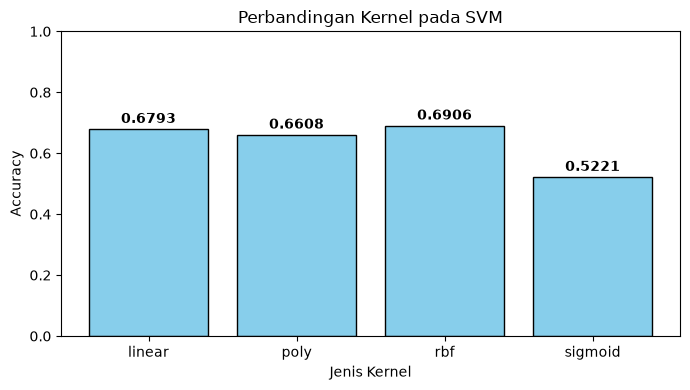

In [16]:
plt.figure(figsize=(7, 4))
plt.bar(kernels, acc_scores, color='skyblue', edgecolor='black')
plt.title('Perbandingan Kernel pada SVM')
plt.xlabel('Jenis Kernel')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
for i, v in enumerate(acc_scores):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Melatih Model SVM Final

In [17]:
start_time = time.perf_counter()

model_svm = SVC(kernel=best_kernel, random_state=42)
model_svm.fit(X_train, y_train_kelas)
y_pred_svm = model_svm.predict(X_test)

end_time = time.perf_counter()

waktu_svm = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model SVM: {waktu_svm:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model SVM: 0.8423 detik


### Evaluasi

In [18]:
acc_svm = accuracy_score(y_test_kelas, y_pred_svm)
prec_svm = precision_score(y_test_kelas, y_pred_svm, average='weighted')
rec_svm = recall_score(y_test_kelas, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test_kelas, y_pred_svm, average='weighted')

print("=== HASIL EVALUASI MODEL SVM ===")
print(f"1. Accuracy       : {acc_svm:.4f} ({acc_svm*100:.2f}%)")
print(f"2. Precision      : {prec_svm:.4f}")
print(f"3. Recall         : {rec_svm:.4f}")
print(f"4. F1-Score       : {f1_svm:.4f}")
print(f"5. Waktu Eksekusi : {waktu_svm:.4f} detik")

=== HASIL EVALUASI MODEL SVM ===
1. Accuracy       : 0.6906 (69.06%)
2. Precision      : 0.6925
3. Recall         : 0.6906
4. F1-Score       : 0.6907
5. Waktu Eksekusi : 0.8423 detik


### Visualisasi Confusion Matrix

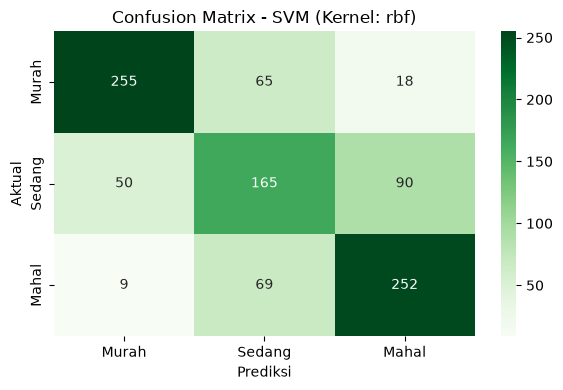

In [19]:
cm_svm = confusion_matrix(y_test_kelas, y_pred_svm)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Murah', 'Sedang', 'Mahal'], 
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.title(f'Confusion Matrix - SVM (Kernel: {best_kernel})')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

### Menyimpan Hasil SVM

In [20]:
hasil_svm = {
    'Model': 'SVM',
    'Accuracy': acc_svm,
    'Precision': prec_svm,
    'Recall': rec_svm,
    'F1-Score': f1_svm,
    'Waktu (Detik)': waktu_svm,
    'y_test_kelas': y_test_kelas,
    'y_pred_kelas': y_pred_svm
}

joblib.dump(hasil_svm, 'hasil_svm.pkl')
print("Hasil evaluasi SVM berhasil disimpan ke 'klasifikasi_model/hasil_svm.pkl'!")

Hasil evaluasi SVM berhasil disimpan ke 'klasifikasi_model/hasil_svm.pkl'!
